In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Decision Tree
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(DATA_DIR / "train_data.csv")
test_data = pd.read_csv(DATA_DIR / "test_data.csv")

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head())

Training dataset: (5616, 20)
Testing dataset: (1405, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No


In [3]:
TARGET_COLUMN = "Churn"

X_train = train_data.drop(columns=[TARGET_COLUMN])
y_train = train_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

X_test = test_data.drop(columns=[TARGET_COLUMN])
y_test = test_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5616, 19)
y_train: (5616,)
X_test: (1405, 19)
y_test: (1405,)


In [4]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 3
Categorical features: 16


In [5]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [6]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Decision Tree preprocessor created successfully!")

Decision Tree preprocessor created successfully!


In [8]:
DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [9]:
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)

print(decision_tree)

DecisionTreeClassifier(random_state=42)


In [10]:
decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", decision_tree)
    ]
)

print("Decision Tree pipeline created successfully!")

Decision Tree pipeline created successfully!


In [11]:
decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [12]:
trained_tree = decision_tree_pipeline.named_steps["classifier"]

print("Tree depth:", trained_tree.get_depth())
print("Number of leaves:", trained_tree.get_n_leaves())
print("Number of nodes:", trained_tree.tree_.node_count)

Tree depth: 24
Number of leaves: 1128
Number of nodes: 2255


In [13]:
y_pred = decision_tree_pipeline.predict(X_test)

y_pred_proba = decision_tree_pipeline.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Churn_Probability": y_pred_proba
})

display(results.head(10))

,Actual,Predicted,Churn_Probability
0,0,1,1.0
1,1,1,1.0
2,1,1,1.0
3,0,0,0.0
4,0,0,0.0
5,0,1,1.0
6,0,0,0.0
7,1,1,1.0
8,0,0,0.0
9,0,0,0.0


In [14]:
decision_tree_metrics = {
    "Model": "Decision Tree",

    "Accuracy": accuracy_score(y_test, y_pred),

    "AUC": roc_auc_score(y_test, y_pred_proba),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "MCC": matthews_corrcoef(y_test, y_pred)
}

decision_tree_metrics_df = pd.DataFrame([
    decision_tree_metrics
])

display(
    decision_tree_metrics_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,0.7146,0.6498,0.4642,0.5054,0.4839,0.2877


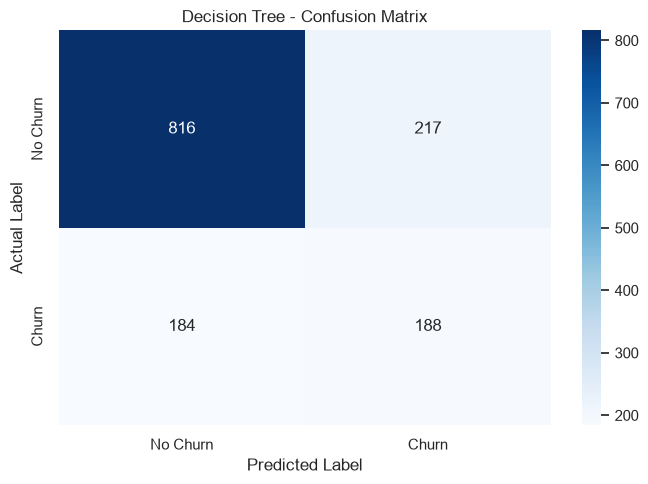

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.8160    0.7899    0.8028      1033
       Churn     0.4642    0.5054    0.4839       372

    accuracy                         0.7146      1405
   macro avg     0.6401    0.6477    0.6433      1405
weighted avg     0.7229    0.7146    0.7183      1405



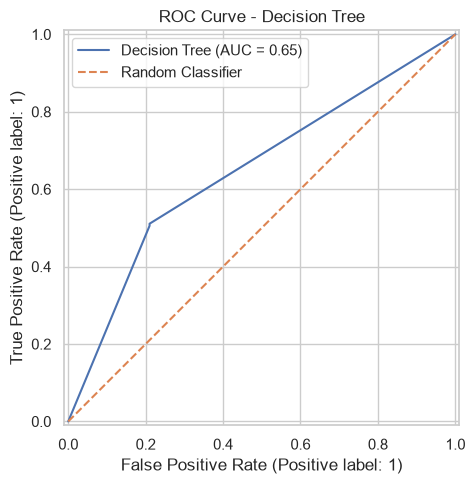

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="Decision Tree",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve - Decision Tree")
ax.legend()

plt.tight_layout()
plt.show()

In [18]:
fitted_preprocessor = decision_tree_pipeline.named_steps["preprocessor"]
fitted_classifier = decision_tree_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_classifier.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(15))

,Feature,Importance
2,num__TotalCharges,0.207407
1,num__MonthlyCharges,0.177567
37,cat__Contract_Month-to-month,0.164926
0,num__tenure,0.108587
17,cat__InternetService_Fiber optic,0.051771
3,cat__gender_Female,0.016482
19,cat__OnlineSecurity_No,0.015224
10,cat__Dependents_Yes,0.013710
42,cat__PaymentMethod_Bank transfer (automatic),0.012057
24,cat__OnlineBackup_Yes,0.011684


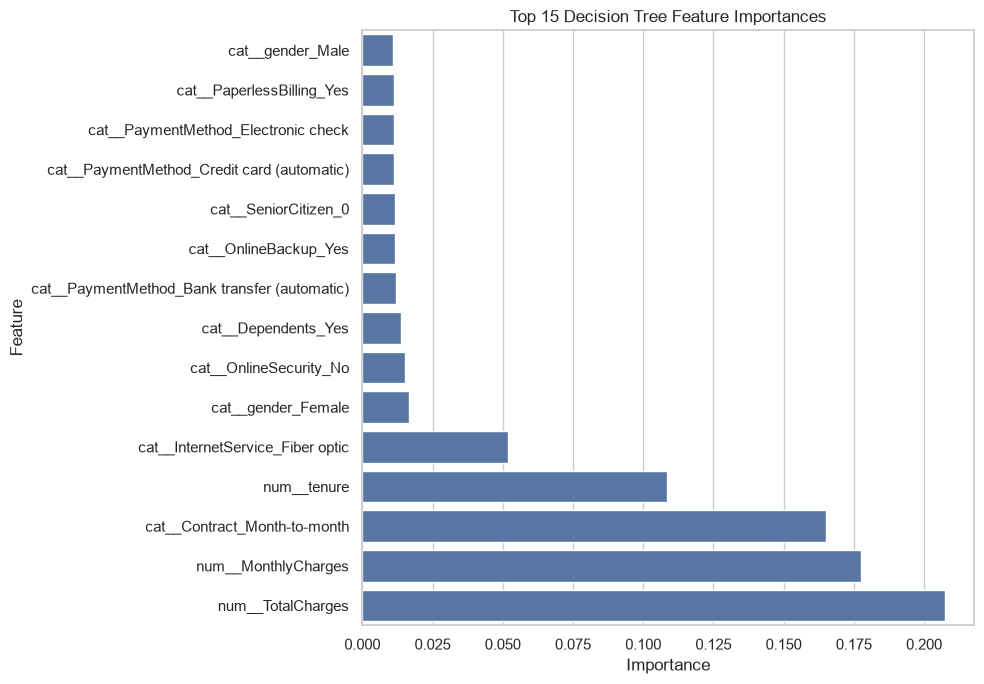

In [19]:
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

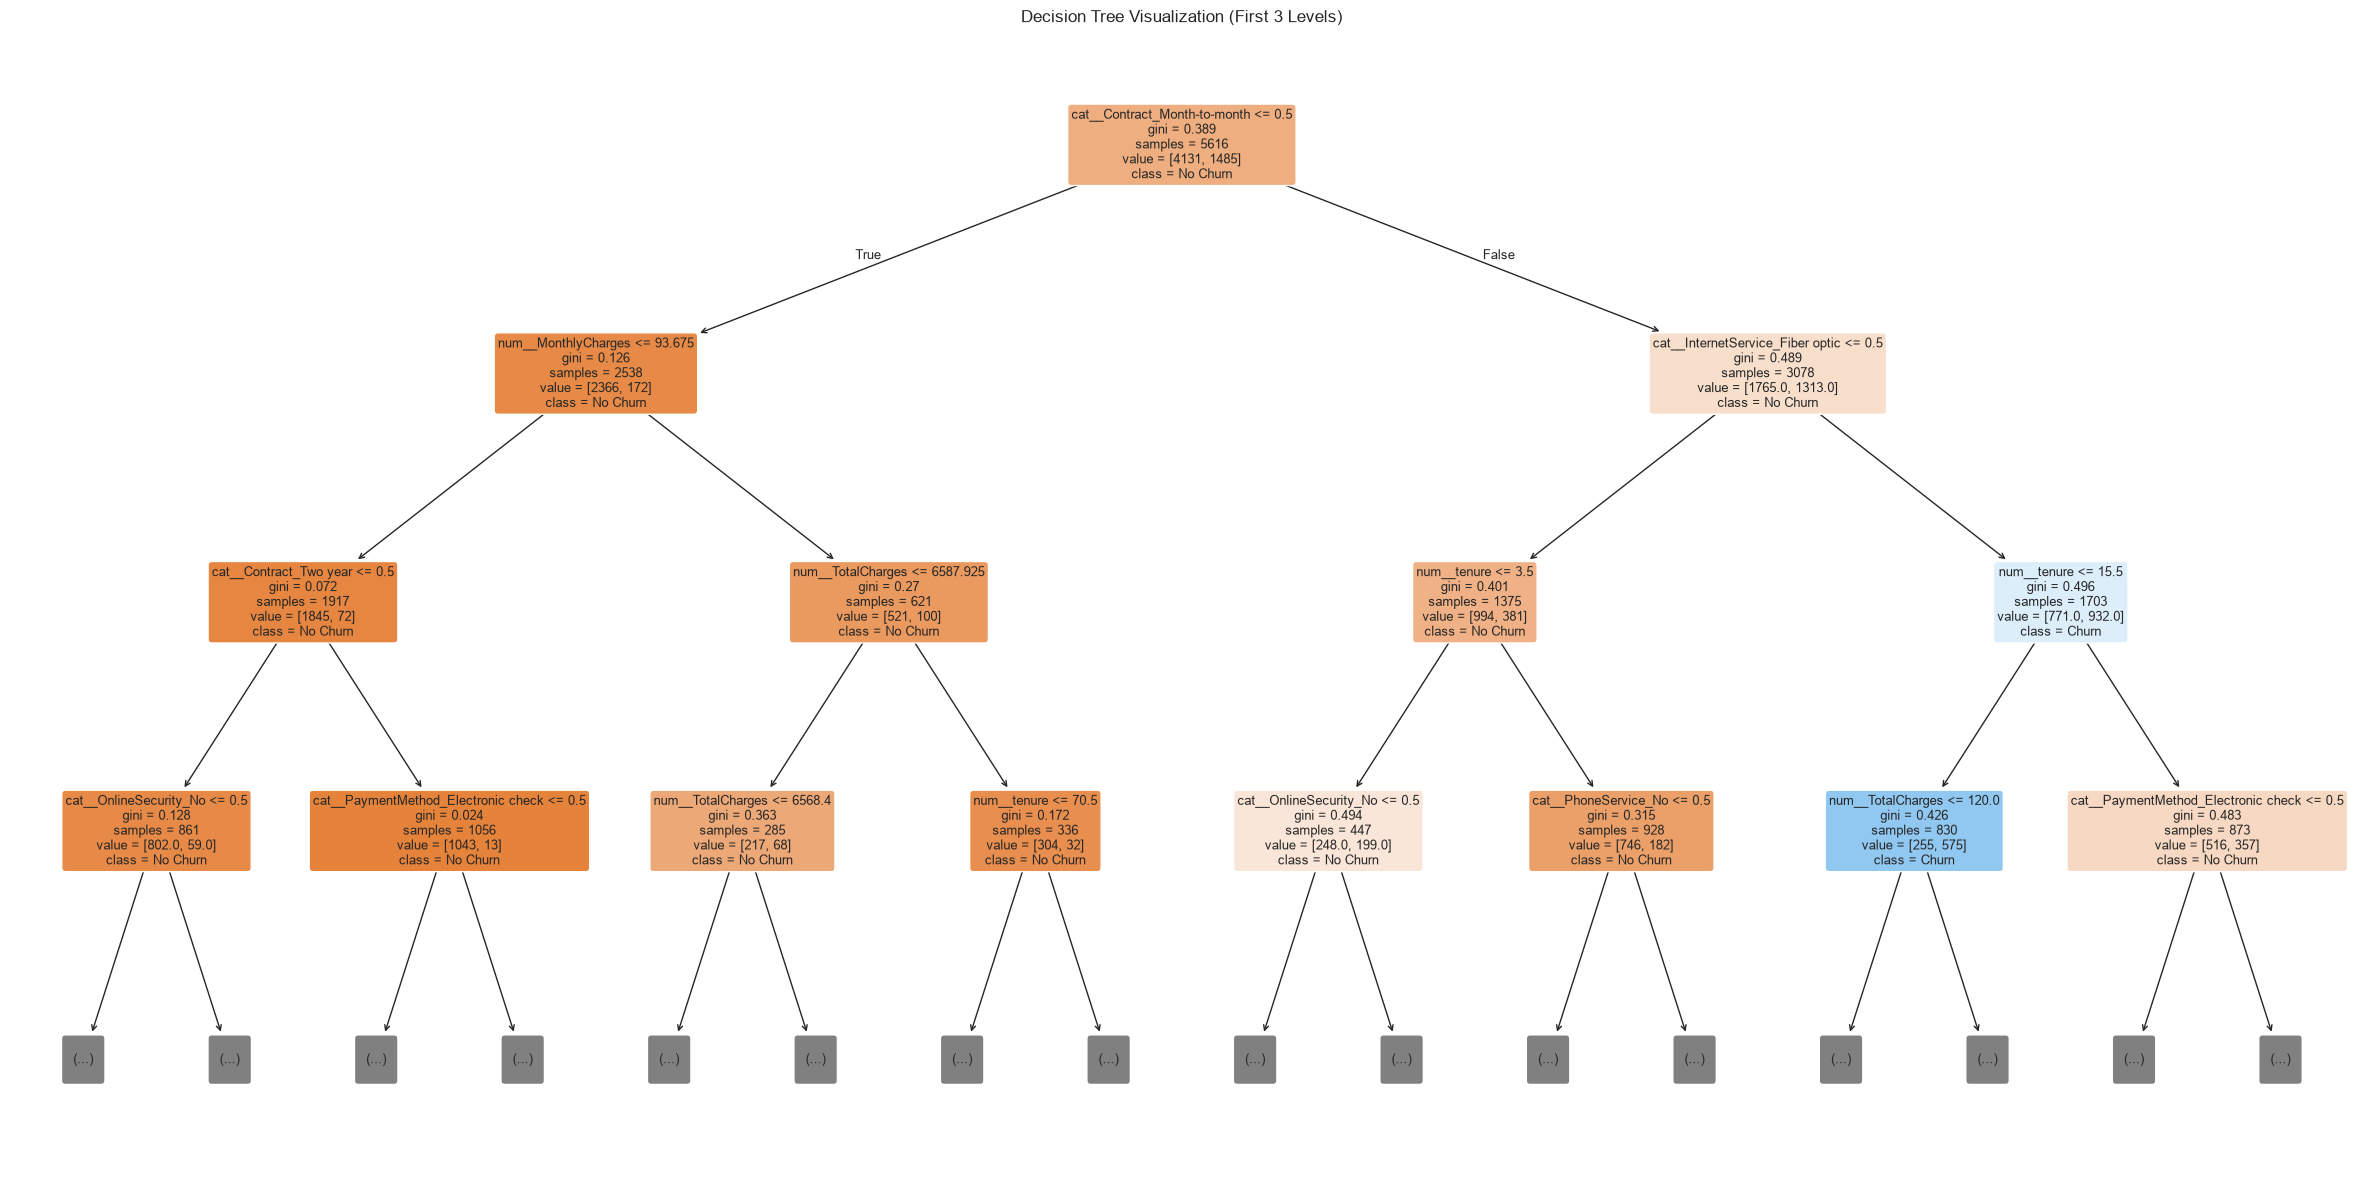

In [20]:
plt.figure(figsize=(24, 12))

plot_tree(
    fitted_classifier,
    feature_names=feature_names,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.tight_layout()
plt.show()

In [21]:
MODEL_PATH = MODEL_DIR / "decision_tree.joblib"

joblib.dump(
    decision_tree_pipeline,
    MODEL_PATH
)

print("Decision Tree model saved successfully!")
print("Location:", MODEL_PATH)

Decision Tree model saved successfully!
Location: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/decision_tree.joblib


In [22]:
decision_tree_metrics_df.to_csv(
    RESULTS_DIR / "decision_tree_metrics.csv",
    index=False
)

print("Decision Tree metrics exported successfully!")

Decision Tree metrics exported successfully!
